# Baseline: 3D scene reconstruction from video with SAM 3 + SAM 3D Objects

This notebook is the **starting point for new work**. It states the goal, the setting, how we evaluate, and the two versions of the pipeline we have today:

1. **Baseline**: SAM 3 masks → SAM 3D Objects used exactly as released;
2. **Known camera**: the same pipeline, with SAM 3D given a metric depth map built from the camera calibration and the ground plane.

It runs nothing heavy. It only **reads the results already produced** by `sam3.ipynb` and `evaluate.ipynb` (folders `sequences/` and `eval_output/`, from the [latest release](https://github.com/alessionovel/sam4d/releases/latest), see the README, *Example data*). It needs no GPU and works on any OS, with any Python that has `numpy`, `pandas`, `matplotlib` and `pillow`.

To produce new results, see [docs/EVALUATION.md](docs/EVALUATION.md). To add a new method to the comparison, see the [last section](#6-starting-point-for-new-methods).

## 1. Goal

**Reconstruct a 3D scene from ordinary video.** For every vehicle in view and every frame we want:

- its **position** in metres,
- its **orientation** (which way it points),
- its **size and shape** (a 3D model),

so that the scene can be rebuilt as a "digital twin": the right objects, in the right place, at the right scale.

The input is a **video**, not a set of unrelated photos, so the reconstruction should also be **consistent over time**: a car does not change size, does not jump between frames, and does not flip front to back from one frame to the next. Getting there means **sharing information between frames**, and it is one of the main goals of the work that starts from this notebook.

**The realistic scenario** we target is a **fixed camera** watching an area where vehicles move (a track, a road, a yard): one RGB camera, no depth sensor, no markers on the vehicles. Because the camera does not move, it is reasonable to assume it can be **calibrated once**: its intrinsics (focal length, principal point) and its pose with respect to the ground are known.

**The pipeline**

```
video ──> SAM 3 ──────────────> SAM 3D Objects ──────────> object in 3D
          text prompt "car"     one frame + one mask       points/mesh + pose (rotation, translation, scale)
          mask per object       -> one object              in the camera frame
          per frame
```

- **SAM 3** (`sam3.ipynb`) finds and tracks every object matching a text prompt and gives one mask per object per frame.
- **SAM 3D Objects** (`sam3d.ipynb`, `evaluate.ipynb`) takes **one image and one mask** and returns the object's 3D shape and its pose relative to the camera. In the two versions below each frame is reconstructed **independently**. This is the starting choice, not a property of the problem: sharing information between frames is the first thing to build on top (see the last section).

## 2. Setting: simulated sequences with ground truth

On real video we can only look at the result. To **measure** it we need to know the true pose and size of the object in every frame, so we use sequences rendered in a simulator (CARLA, map *Vadena*), where everything is known exactly.

All sequences show **one car** (the E-Agle "Kraken" Formula Student car, 2.90 x 1.51 x 1.15 m) seen by **one static, ideal pinhole camera** at 1920x1080, 30 fps. Each sequence folder contains the frames (`rgb/`), the true masks (`masks/`), the camera calibration and pose (`camera.json`) and the true pose of the car in every frame (`gt.csv`). The format is described in [docs/EVALUATION.md](docs/EVALUATION.md) and in each sequence's own `README.md`.

The next cells load the sequences that are present and show one frame of each, with the true mask outlined in green.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd()                     # the repository root (where this notebook is)
SEQUENCES = ROOT / "sequences"
EVAL = ROOT / "eval_output"
for p in (SEQUENCES, EVAL):
    if not p.is_dir():
        raise FileNotFoundError(f"{p} not found. Download the example data first (README, 'Example data').")

pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")


def load_sequence(name):
    """Camera and ground truth of one sequence."""
    seq = SEQUENCES / name
    cam = json.load(open(seq / "camera.json"))
    world = cam.get("world") or cam.get("rh_world")
    gt = pd.read_csv(seq / "gt.csv", index_col="frame")
    return {
        "name": name, "dir": seq, "gt": gt,
        "K": np.array(cam["K"], float), "width": int(cam["width"]), "height": int(cam["height"]),
        "R_wc": np.array(world["R_world_from_cam_opencv"], float),     # camera (OpenCV axes) -> world
        "t_wc": np.array(world["position_m"], float),                  # camera position in the world, m
        "frames": sorted(int(p.stem) for p in (seq / "rgb").glob("*.png")),
    }


SEQ = {p.name: load_sequence(p.name) for p in sorted(SEQUENCES.iterdir()) if (p / "gt.csv").exists()}

rows = []
for name, s in SEQ.items():
    gt = s["gt"].loc[s["frames"]]
    ground_z = gt.world_z.median() - 1.146 / 2             # the car's box centre is half its height above the ground
    rows.append({
        "sequence": name, "frames": len(s["frames"]),
        "horizontal FOV (deg)": np.degrees(2 * np.arctan(s["width"] / (2 * s["K"][0, 0]))),
        "camera height (m)": s["t_wc"][2] - ground_z,
        "distance to car (m)": f"{np.linalg.norm(gt[['cam_x', 'cam_y', 'cam_z']].values, axis=1).min():.1f}-"
                               f"{np.linalg.norm(gt[['cam_x', 'cam_y', 'cam_z']].values, axis=1).max():.1f}",
        "car, % of image (median)": 100 * gt.mask_frac.median(),
        "frames cut by border": int(gt.truncated.sum()),
    })
pd.DataFrame(rows).set_index("sequence")

,frames,horizontal FOV (deg),camera height (m),distance to car (m),"car, % of image (median)",frames cut by border
sequence,,,,,,
lap_01_slalom,371,75.000,5.999,7.3-37.7,1.041,132
lap_02_circle,751,47.000,3.500,8.6-15.4,3.105,71
lap_03_turntable,751,29.000,2.000,10.1-10.1,13.945,0


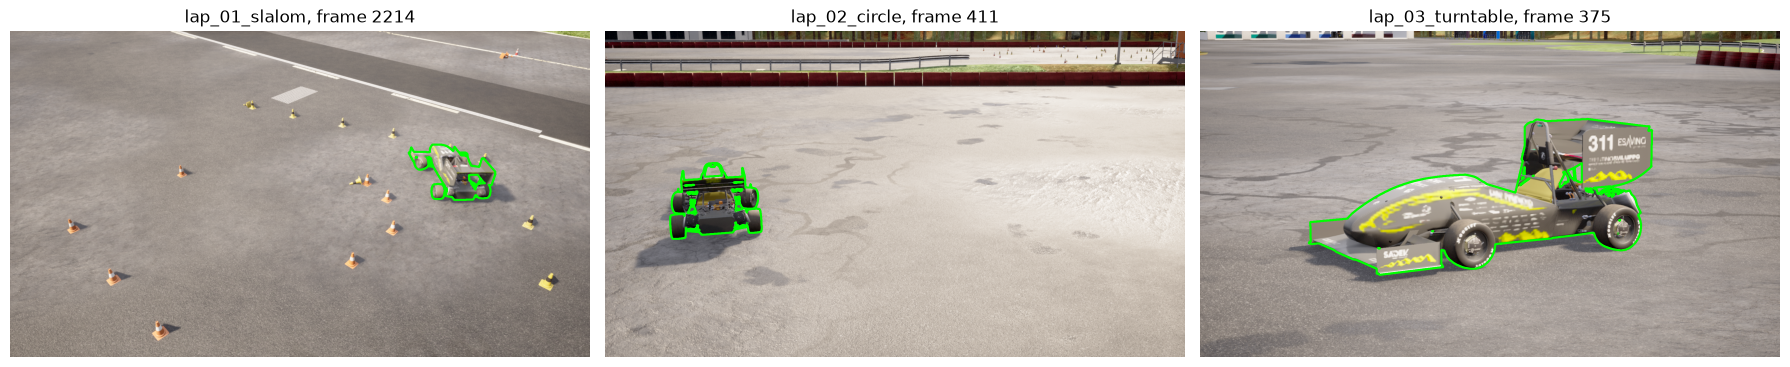

In [2]:
fig, axes = plt.subplots(1, len(SEQ), figsize=(6 * len(SEQ), 3.6), squeeze=False)
for ax, (name, s) in zip(axes[0], SEQ.items()):
    usable = [f for f in s["frames"] if (s["dir"] / "masks" / f"{f:06d}.png").exists() and not s["gt"].truncated[f]]
    f = usable[len(usable) // 2]
    ax.imshow(Image.open(s["dir"] / "rgb" / f"{f:06d}.png").convert("RGB"))
    mask = np.array(Image.open(s["dir"] / "masks" / f"{f:06d}.png").convert("L")) > 127
    ax.contour(mask, levels=[0.5], colors="lime", linewidths=1.5)
    ax.set_title(f"{name}, frame {f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

The three sequences go from easy to hard:

| Sequence | What happens | Why it is useful |
|---|---|---|
| `lap_03_turntable` | the car turns in place, close to a low camera with a narrow lens | every viewing angle once, large in the image |
| `lap_02_circle` | the car drives slow tight circles | real motion, medium size, sometimes cut by the border |
| `lap_01_slalom` | the car drives through a slalom under a high, wide-angle camera | closest to the realistic scenario: small car, changing distance |

## 3. How we evaluate

For every evaluated frame, `evaluate.ipynb` reconstructs the car with SAM 3D and compares the result with `gt.csv`. Three steps make the comparison meaningful:

1. **Same camera frame.** SAM 3D's pose is converted from PyTorch3D axes (x left, y up, z forward) to the ground truth's OpenCV axes (x right, y down, z forward).
2. **Axis alignment.** SAM 3D chooses its own axes for the object. One rotation from its axes to the true ones (x forward, y left, z up) is estimated over the whole sequence and applied to every frame. The rotation error is measured after it.
3. **Centre and size** of the reconstruction are taken from the box around its points (1st-99th percentile along each true axis), because the ground truth gives the centre of the car's 3D box.

**Main metrics** (per frame, in `metrics.csv`; the summary tables below use the **median** over frames):

| Metric | Meaning |
|---|---|
| `mask_iou` | SAM 3 mask vs true mask |
| `trans_err_m` | distance between predicted and true centre |
| `depth_err_m` | the part of it along the camera's optical axis (negative = too close) |
| `lateral_err_m` | the part perpendicular to the viewing ray (a shift in the image) |
| `rot_err_deg` | orientation error after the axis alignment; near 180 = front and back swapped |
| `heading_err_deg` | error of the forward direction on the ground plane |
| `L/W/H_pred_m` | size of the reconstruction, to compare with 2.90 x 1.51 x 1.15 m |
| `reproj_iou` | reconstruction projected with the true camera vs true mask |

**2D mask comparison** (computed in this notebook from the saved reconstructions and the true masks). Three masks exist for every frame: the **true mask** (from the simulator), the **SAM 3 mask** (given to SAM 3D) and the **reprojection**, the silhouette of SAM 3D's reconstruction projected into the image with the true camera. They are compared pairwise:

| Comparison | What it tells |
|---|---|
| SAM 3 vs true | quality of the segmentation (step 1 of the pipeline) |
| reprojection vs true | whether the 3D result, placed in the scene, covers the car in the image: shape, position and scale together |
| reprojection vs SAM 3 | whether SAM 3D explains the mask it was given |

For each pair: **IoU** (overlap / union), **precision** (fraction of the first mask that lies on the second) and **recall** (fraction of the second mask covered by the first). Precision below recall means the first mask is too large or shifted; recall below precision means it is too small.

**Temporal consistency** (computed in this notebook from the saved reconstructions, over consecutive evaluated frames):

| Metric | Meaning |
|---|---|
| `size CV (%)` | variation of the predicted length over the sequence (std / mean). The car never changes size, so the ideal is 0 |
| `step err (m)` | error of the motion between two consecutive evaluated frames: predicted displacement minus true displacement. Measures jitter, independently of a constant offset |
| `rel rot err (deg)` | error of the rotation between two consecutive evaluated frames: predicted relative rotation vs true relative rotation |
| `flips` | consecutive pairs whose relative rotation is wrong by more than 90° (the orientation jumped) |

**What to keep in mind when reading the numbers**

- **Which frames are evaluated is decided with the ground truth**: frames where the car is cut by the image border or covers less than 0.5 % of the image are skipped. The numbers describe the good cases.
- **The axis alignment is fitted on the same frames it is used on**, so `rot_err_deg` measures consistency across frames and is optimistic on short runs.
- **The SAM 3 mask is the one that overlaps the true mask most.** In the runs below SAM 3 found exactly one object in every frame, so this never made a choice. With several vehicles it would.
- There is **one car** and **no occlusion**.
- The full-pipeline runs evaluate about **3 frames per second** (one frame every 10), so "consecutive" means 1/3 s apart. Temporal methods may want denser runs (`TARGET_FPS` in `sam3.ipynb` and `evaluate.ipynb`).

## 4. The two versions of the pipeline

Both use **SAM 3 masks** (`MASK_SOURCE = "sam3"`), so they are the full pipeline, video in, 3D out. They differ only in what SAM 3D knows about the camera (`CAMERA_MODE` in `evaluate.ipynb`).

### Baseline: `estimate`

SAM 3D exactly as released. To place the object it needs a 3D point for every pixel (a *point map*). It gets it from a monocular depth model (MoGe), which has to guess both the **focal length** and the **scale** of the depth from the image alone. A single image cannot tell a small object nearby from a large one far away, so the returned distance and size are not reliable in metres, even when the shape and the position in the image are right.

### Known camera: `known`

Uses what a fixed, calibrated camera gives for free: the true intrinsics and where the ground is.

1. For every pixel, compute the **true depth of the ground** along its viewing ray (camera pose + ground height).
2. Run MoGe with the **true field of view**, so it doesn't have to guess the focal length.
3. Take the **ground pixels around the object** (not the object itself) and compute `scale = median(true ground depth / MoGe depth)`.
4. Multiply MoGe's depth by that scale, back-project it with the true intrinsics and **give this point map to SAM 3D** instead of its own.

It uses no information about the object: only the calibration and the ground height. (For `lap_01_slalom` the ground height is currently derived from the car's true height because the sequence does not record it. It is one constant for the sequence, but it should be replaced by a `ground_z` value in the data.)

The next cell loads every run of the full pipeline found in `eval_output/`.

In [3]:
FLIP = np.diag([-1.0, -1.0, 1.0])     # PyTorch3D camera axes <-> OpenCV camera axes


def quat_to_R(w, x, y, z):
    n = np.sqrt(w * w + x * x + y * y + z * z)
    w, x, y, z = w / n, x / n, y / n, z / n
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                     [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                     [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])


def predicted_pose(npz_path, C):
    """Rotation (true object axes -> camera) and centre of one saved reconstruction, in the OpenCV camera frame
    (same computation as evaluate.ipynb, Cell 6)."""
    d = np.load(npz_path)
    M = FLIP @ quat_to_R(*d["quat_wxyz"]).T                      # SAM 3D object axes -> camera
    pts = (C @ (float(d["scale"][0]) * d["xyz_local"].astype(float)).T).T      # points in the true object axes
    lo, hi = np.percentile(pts, [1, 99], axis=0)
    R_pred = M @ C.T
    return R_pred, R_pred @ ((lo + hi) / 2) + FLIP @ d["translation"]


def load_run(run_dir):
    """One evaluate.ipynb output folder: per-frame metrics plus the predicted and true centre in the world frame."""
    run_dir = Path(run_dir)
    summary = json.load(open(run_dir / "summary.json"))
    settings = summary.get("settings", {})
    seq = SEQ[Path(summary["sequence"]).name]
    df = pd.read_csv(run_dir / "metrics.csv", index_col="frame")
    C = np.array(summary["axis_alignment_sam3d_to_object"])
    poses = [predicted_pose(run_dir / "reconstructions" / f"frame_{f:06d}.npz", C) for f in df.index]
    pred = np.array([c for _, c in poses])
    true = seq["gt"].loc[df.index, ["cam_x", "cam_y", "cam_z"]].values
    gt = seq["gt"].loc[df.index]
    R_true = [quat_to_R(r.cam_qw, r.cam_qx, r.cam_qy, r.cam_qz) for r in gt.itertuples()]
    for name, cam_pts in (("pred", pred), ("true", true)):
        w = cam_pts @ seq["R_wc"].T + seq["t_wc"]
        df[f"{name}_world_x"], df[f"{name}_world_y"], df[f"{name}_world_z"] = w.T
    return {
        "dir": run_dir, "sequence": seq["name"], "mask_source": summary["mask_source"],
        # runs made before CAMERA_MODE existed have no "camera_mode": they are "estimate"
        "method": settings.get("method") or settings.get("camera_mode", "estimate"),
        "true_size": np.array(summary["true_size_lwh"]), "metrics": df,
        # per frame, in the OpenCV camera frame: rotation (object -> camera) and centre, predicted and true
        "R_pred": np.array([R for R, _ in poses]), "R_true": np.array(R_true),
        "c_pred_cam": pred, "c_true_cam": true, "C": C,
    }


RUNS = {}                              # (sequence, method) -> run, full pipeline only
for p in sorted(EVAL.glob("*/summary.json")):
    if not (p.parent / "metrics.csv").exists():
        continue
    if Path(json.load(open(p))["sequence"]).name not in SEQ:
        continue
    run = load_run(p.parent)
    if run["mask_source"] == "sam3":
        RUNS[(run["sequence"], run["method"])] = run

for (seq_name, method), run in RUNS.items():
    print(f"{seq_name:18s} {method:9s} {len(run['metrics']):3d} frames   {run['dir'].relative_to(ROOT)}")

lap_01_slalom      estimate   20 frames   eval_output/lap_01_slalom_sam3
lap_01_slalom      known      20 frames   eval_output/lap_01_slalom_sam3_known
lap_03_turntable   estimate   76 frames   eval_output/lap_03_turntable_sam3
lap_03_turntable   known      76 frames   eval_output/lap_03_turntable_sam3_known


## 5. Results

One row per sequence and method: the **median over the evaluated frames**, plus the number of frames whose rotation error is above 90° (front and back swapped, or similar).

In [4]:
def summarize(run):
    df = run["metrics"]
    L, W, H = run["true_size"]
    return {
        "frames": len(df),
        "mask IoU": df.mask_iou.median(),
        "centre err (m)": df.trans_err_m.median(),
        "depth err (m)": df.depth_err_m.median(),
        "lateral err (m)": df.lateral_err_m.median(),
        "rot err (deg)": df.rot_err_deg.median(),
        "|heading err| (deg)": df.heading_err_deg.abs().median(),
        "rot err > 90": int((df.rot_err_deg > 90).sum()),
        "L err (%)": 100 * (df.L_pred_m.median() / L - 1),
        "W err (%)": 100 * (df.W_pred_m.median() / W - 1),
        "H err (%)": 100 * (df.H_pred_m.median() / H - 1),
        "reproj IoU": df.reproj_iou.median(),
    }


table = pd.DataFrame({key: summarize(run) for key, run in RUNS.items()}).T
table.index.names = ["sequence", "method"]
table["frames"] = table["frames"].astype(int)
table["rot err > 90"] = table["rot err > 90"].astype(int)
table

frames  mask IoU  centre err (m)  depth err (m)  lateral err (m)  rot err (deg)  |heading err| (deg)  rot err > 90  L err (%)  W err (%)  H err (%)  reproj IoU
sequence         method                                                                                                                                                                   
lap_01_slalom    estimate      20     0.908          10.410         -9.360            0.015         12.348                5.710             2    -88.426    -87.857    -89.691       0.600
                 known         20     0.908           0.236          0.186            0.110         12.233                5.675             2     -4.882     -0.140    -16.839       0.652
lap_03_turntable estimate      76     0.970           9.217         -9.217            0.008          3.685                3.348             7    -87.969    -87.004    -88.456       0.359
                 known         76     0.970           1.168          1.164            0.085          3.868                3.359             7      5.409     12.677      1.430       0.751

### 2D mask comparison

The reprojection is drawn the same way as in `evaluate.ipynb` (Cell 6): each point of the reconstruction as a small disc about one SAM 3D voxel wide, then small gaps closed. Its IoU with the true mask should match `reproj_iou` in `metrics.csv`, which the next cell checks.

In [5]:
def dilate(m, r):
    """Binary dilation with a (2r+1) x (2r+1) square, numpy only."""
    out = m.copy()
    for k in range(1, r + 1):                      # rows
        out[k:] |= m[:-k]
        out[:-k] |= m[k:]
    rows = out.copy()
    for k in range(1, r + 1):                      # columns
        out[:, k:] |= rows[:, :-k]
        out[:, :-k] |= rows[:, k:]
    return out


def erode(m, r):
    return ~dilate(~m, r)


def reprojection(npz_path, R_pred, c_pred, C, seq):
    """Silhouette of a saved reconstruction projected with the true intrinsics (as in evaluate.ipynb)."""
    d = np.load(npz_path)
    s = float(d["scale"][0])
    pts = (C @ (s * d["xyz_local"].astype(float)).T).T
    lo, hi = np.percentile(pts, [1, 99], axis=0)
    pts_cv = (R_pred @ (pts - (lo + hi) / 2).T).T + c_pred
    K, H, W = seq["K"], seq["height"], seq["width"]
    pts_cv = pts_cv[pts_cv[:, 2] > 0.01]
    uv = np.round((K @ (pts_cv / pts_cv[:, 2:3]).T).T[:, :2]).astype(int)
    r = max(1, int(np.ceil(0.75 * K[0, 0] * (s / 64) / c_pred[2])))
    sil = np.zeros((H, W), bool)
    for du in range(-r, r + 1):
        for dv in range(-r, r + 1):
            if du * du + dv * dv <= r * r:
                u, v = uv[:, 0] + du, uv[:, 1] + dv
                ok = (u >= 0) & (u < W) & (v >= 0) & (v < H)
                sil[v[ok], u[ok]] = True
    return erode(dilate(sil, r), r)                 # close small gaps between the discs


def compare(a, b):
    """IoU, precision (a on b) and recall (b covered by a) of two binary masks."""
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return (inter / union if union else 0.0, inter / a.sum() if a.sum() else 0.0, inter / b.sum() if b.sum() else 0.0)


def masks_of_frame(run, i):
    """True mask, SAM 3 mask (the one SAM 3D got) and reprojection for the i-th evaluated frame of a run."""
    f = run["metrics"].index[i]
    seq = SEQ[run["sequence"]]
    p = run["dir"] / "reconstructions" / f"frame_{f:06d}.npz"
    d = np.load(p)
    sam3 = np.unpackbits(d["mask"])[: int(np.prod(d["mask_shape"]))].reshape(d["mask_shape"]).astype(bool)
    gt_path = seq["dir"] / "masks" / f"{f:06d}.png"
    true = np.array(Image.open(gt_path).convert("L")) > 127 if gt_path.exists() else np.zeros_like(sam3)
    return f, true, sam3, reprojection(p, run["R_pred"][i], run["c_pred_cam"][i], run["C"], seq)


def mask_metrics(run):
    """Per-frame 2D metrics of a run, added to run["metrics"]."""
    rows = []
    for i in range(len(run["metrics"])):
        f, true, sam3, rep = masks_of_frame(run, i)
        row = {"frame": f}
        pairs = {"sam3_vs_true": (sam3, true), "reproj_vs_true": (rep, true), "reproj_vs_sam3": (rep, sam3)}
        for name, (a, b) in pairs.items():
            row[f"{name}_iou"], row[f"{name}_precision"], row[f"{name}_recall"] = compare(a, b)
        rows.append(row)
    m = pd.DataFrame(rows).set_index("frame")
    run["metrics"] = run["metrics"].drop(columns=m.columns, errors="ignore").join(m)
    return m


for key, run in RUNS.items():
    m = mask_metrics(run)
    diff = (m.reproj_vs_true_iou - run["metrics"].reproj_iou).abs()
    print(f"{key[0]:18s} {key[1]:9s} reprojection IoU vs evaluate.ipynb: median difference {diff.median():.3f}, max {diff.max():.3f}")

lap_01_slalom      estimate  reprojection IoU vs evaluate.ipynb: median difference 0.000, max 0.000
lap_01_slalom      known     reprojection IoU vs evaluate.ipynb: median difference 0.000, max 0.000
lap_03_turntable   estimate  reprojection IoU vs evaluate.ipynb: median difference 0.000, max 0.000
lap_03_turntable   known     reprojection IoU vs evaluate.ipynb: median difference 0.000, max 0.000


In [6]:
def mask_table(run):
    df = run["metrics"]
    out = {}
    for name, label in (("sam3_vs_true", "SAM 3 vs true"), ("reproj_vs_true", "reproj vs true"),
                        ("reproj_vs_sam3", "reproj vs SAM 3")):
        for k in ("iou", "precision", "recall"):
            out[(label, k)] = df[f"{name}_{k}"].median()
    return out


masks_table = pd.DataFrame({key: mask_table(run) for key, run in RUNS.items()}).T
masks_table.index.names = ["sequence", "method"]
masks_table

SAM 3 vs true                  reproj vs true                  reproj vs SAM 3                 
                                    iou precision recall            iou precision recall             iou precision recall
sequence         method                                                                                                  
lap_01_slalom    estimate         0.905     0.948  0.968          0.600     0.690  0.837           0.629     0.694  0.894
                 known            0.905     0.948  0.968          0.652     0.737  0.869           0.666     0.730  0.899
lap_03_turntable estimate         0.969     0.992  0.984          0.359     0.367  0.950           0.356     0.361  0.954
                 known            0.969     0.992  0.984          0.751     0.793  0.956           0.756     0.784  0.965

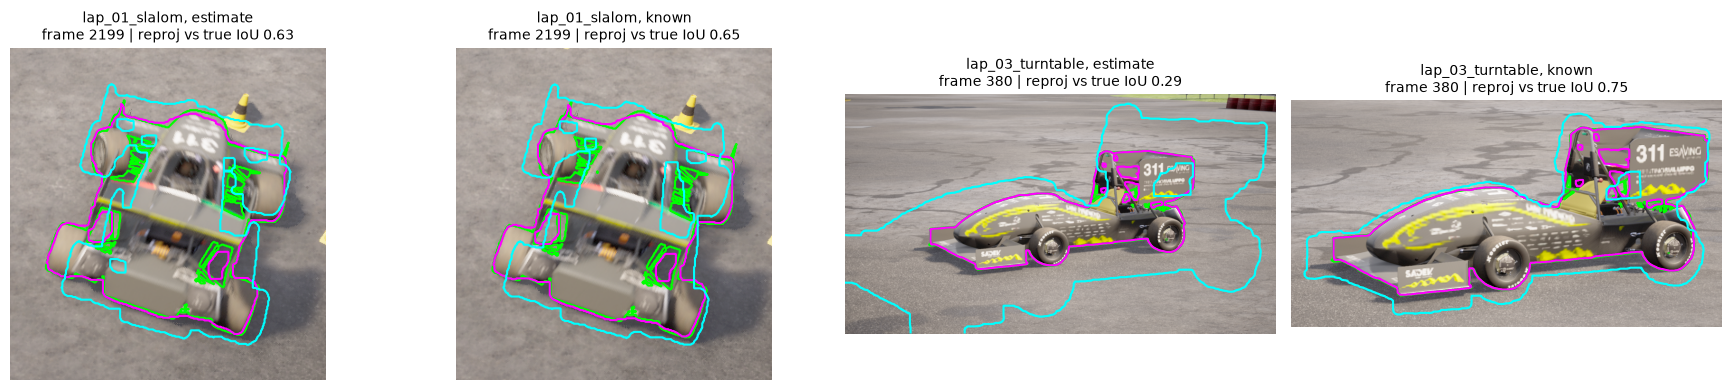

In [7]:
# One frame per run (the middle evaluated frame), cropped around the car.
# green = true mask, magenta = SAM 3 mask, cyan = reprojection of the 3D result
fig, axes = plt.subplots(1, len(RUNS), figsize=(4.5 * len(RUNS), 4), squeeze=False)
for ax, (key, run) in zip(axes[0], RUNS.items()):
    i = len(run["metrics"]) // 2
    f, true, sam3, rep = masks_of_frame(run, i)
    img = np.array(Image.open(SEQ[run["sequence"]]["dir"] / "rgb" / f"{f:06d}.png").convert("RGB"))
    ys, xs = np.where(true | sam3 | rep)
    pad = 40
    y0, y1, x0, x1 = max(0, ys.min() - pad), ys.max() + pad, max(0, xs.min() - pad), xs.max() + pad
    ax.imshow(img[y0:y1, x0:x1])
    for m, color in ((true, "lime"), (sam3, "magenta"), (rep, "cyan")):
        ax.contour(m[y0:y1, x0:x1], levels=[0.5], colors=color, linewidths=1.5)
    iou = run["metrics"].loc[f, "reproj_vs_true_iou"]
    ax.set_title(f"{key[0]}, {key[1]}\nframe {f} | reproj vs true IoU {iou:.2f}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Temporal consistency.** The same runs, measured over consecutive evaluated frames (see the table in section 3). Pairs further apart than one sampling step (where frames were skipped) are left out.

In [8]:
def angle_deg(R):
    return float(np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))))


def temporal(run):
    df = run["metrics"]
    frames = df.index.values
    step = np.median(np.diff(frames))
    pairs = [i for i in range(len(frames) - 1) if frames[i + 1] - frames[i] == step]
    step_err = [np.linalg.norm((run["c_pred_cam"][i + 1] - run["c_pred_cam"][i])
                               - (run["c_true_cam"][i + 1] - run["c_true_cam"][i])) for i in pairs]
    rel_rot_err = [angle_deg((run["R_pred"][i].T @ run["R_pred"][i + 1]).T @ (run["R_true"][i].T @ run["R_true"][i + 1]))
                   for i in pairs]
    return {
        "pairs": len(pairs),
        "size CV (%)": 100 * df.L_pred_m.std() / df.L_pred_m.mean(),
        "step err (m), median": np.median(step_err),
        "step err (m), max": np.max(step_err),
        "rel rot err (deg), median": np.median(rel_rot_err),
        "flips": int(np.sum(np.array(rel_rot_err) > 90)),
    }


temporal_table = pd.DataFrame({key: temporal(run) for key, run in RUNS.items()}).T
temporal_table.index.names = ["sequence", "method"]
temporal_table[["pairs", "flips"]] = temporal_table[["pairs", "flips"]].astype(int)
temporal_table

pairs  size CV (%)  step err (m), median  step err (m), max  rel rot err (deg), median  flips
sequence         method                                                                                                 
lap_01_slalom    estimate     18        7.012                 1.220              1.843                      3.635      2
                 known        18        7.158                 0.135              0.413                      3.668      2
lap_03_turntable estimate     75        5.346                 0.015              0.074                      1.519      6
                 known        75        5.201                 0.110              0.635                      1.637      6

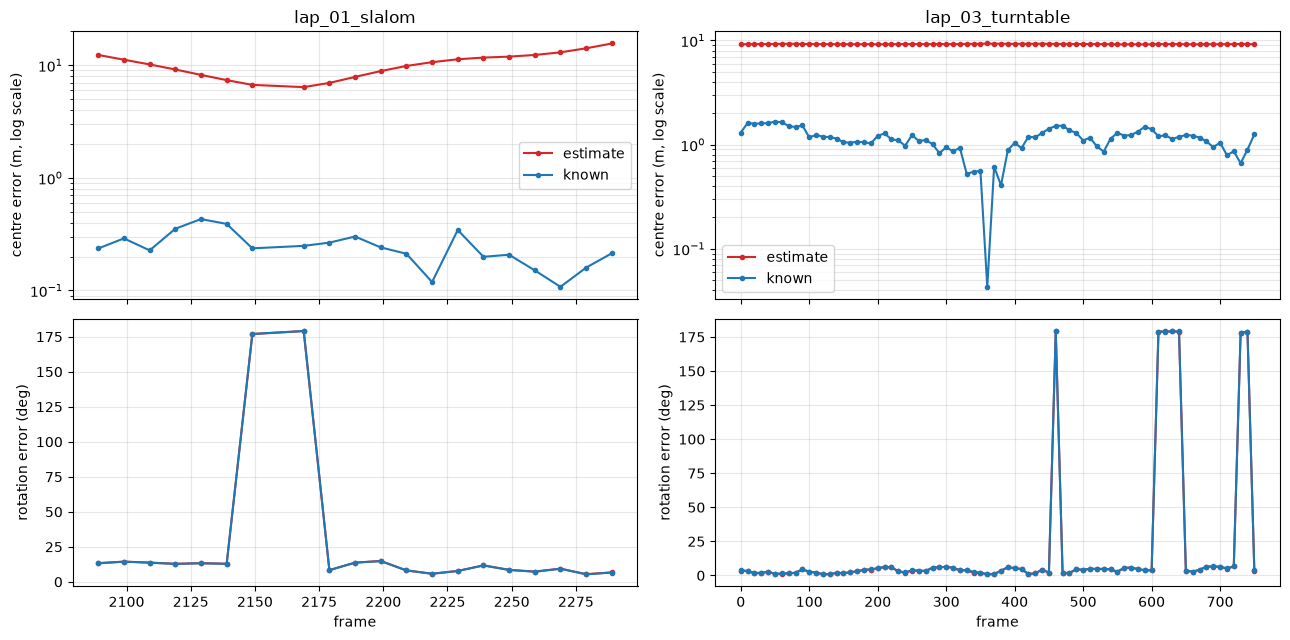

In [9]:
COLORS = {"estimate": "tab:red", "known": "tab:blue"}
seq_names = sorted({s for s, _ in RUNS})

fig, axes = plt.subplots(2, len(seq_names), figsize=(6.5 * len(seq_names), 6.5), sharex="col", squeeze=False)
for col, seq_name in enumerate(seq_names):
    for (s, method), run in RUNS.items():
        if s != seq_name:
            continue
        df, c = run["metrics"], COLORS.get(method)
        axes[0, col].plot(df.index, df.trans_err_m, "o-", ms=3, color=c, label=method)
        axes[1, col].plot(df.index, df.rot_err_deg, "o-", ms=3, color=c, label=method)
    axes[0, col].set_yscale("log")
    axes[0, col].set_title(seq_name)
    axes[0, col].set_ylabel("centre error (m, log scale)")
    axes[1, col].set_ylabel("rotation error (deg)")
    axes[1, col].set_xlabel("frame")
    axes[0, col].legend()
    for ax in axes[:, col]:
        ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

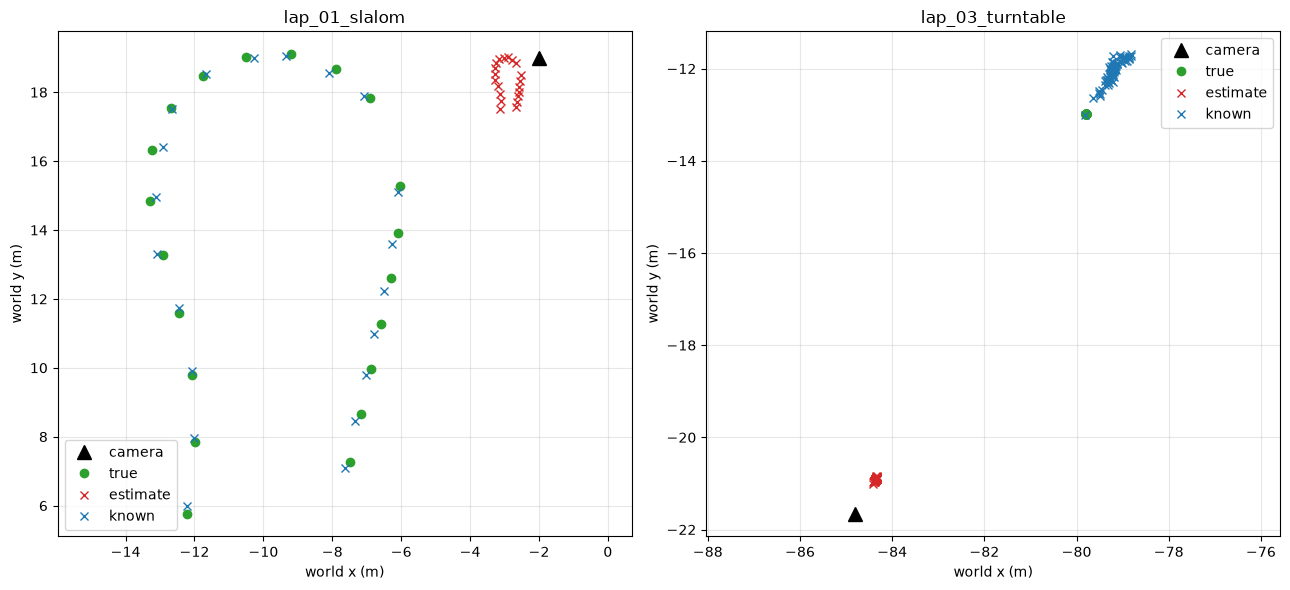

In [10]:
# Top view (world x-y plane): true and predicted centre of the car, and the camera
fig, axes = plt.subplots(1, len(seq_names), figsize=(6.5 * len(seq_names), 6), squeeze=False)
for ax, seq_name in zip(axes[0], seq_names):
    cam = SEQ[seq_name]["t_wc"]
    ax.plot(cam[0], cam[1], "k^", ms=10, label="camera")
    first = True
    for (s, method), run in RUNS.items():
        if s != seq_name:
            continue
        df = run["metrics"]
        if first:
            ax.plot(df.true_world_x, df.true_world_y, "o", color="tab:green", ms=6, label="true")
            first = False
        ax.plot(df.pred_world_x, df.pred_world_y, "x", color=COLORS.get(method), ms=6, label=method)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(seq_name)
    ax.set_xlabel("world x (m)"); ax.set_ylabel("world y (m)")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### Reading the results

With the data of release `v0.2.1` (`lap_01_slalom`: 20 frames, `lap_03_turntable`: 76 frames):

**Baseline (`estimate`)**
- The car is placed about **9-10 m too close** to the camera and comes out about **8 times too small** (around 0.34 m long instead of 2.90 m). In the top view the predictions sit next to the camera.
- The **lateral error is 1-2 cm**: the car is on the right viewing ray, at the wrong distance. The error is almost entirely one of metric scale.
- On the turntable SAM 3D also assumes a focal length far from the true one (the lens is narrow, 29°), so the reconstruction projected with the true camera matches the mask poorly.

**Known camera (`known`)**
- The centre error drops to **0.24 m on the slalom** and **1.2 m on the turntable**, and the size becomes realistic (within about 5 % on the slalom except the height, which is about 17 % too low; 1-13 % too large on the turntable).
- **The turntable is worse than the slalom**, although it is the easier sequence for the shape. The remaining error is almost all depth (the car is placed too far and comes out too large, the same scale error), and it is the same with ground-truth masks, so it does not come from SAM 3. The likely place to look is the ground-plane scale: this camera is low (2 m) and looks at the ground at a shallow angle. **Open question.**
- **Rotation does not change**: the known camera fixes scale, not orientation.

**Both**
- The median rotation error is about 4° on the turntable and 12° on the slalom, but a few frames are **wrong by more than 90°** (2 of 20 on the slalom, 7 of 76 on the turntable). Each frame is reconstructed on its own, so nothing stops the orientation from flipping between consecutive frames.
- SAM 3 is not the bottleneck here: mask IoU is 0.91-0.97 and it finds the car in every evaluated frame.

**2D masks**
- **SAM 3 is good**: IoU 0.91 on the slalom and 0.97 on the turntable, with precision and recall both above 0.94. (These IoUs are computed on the mask SAM 3D received, after `evaluate.ipynb` cleaned it, so they can differ by a few thousandths from `mask IoU` in the first table.)
- **The reprojection is always too large**: precision is lower than recall in every run. The 3D result covers almost all of the car (recall 0.84-0.96) but also a lot around it.
- **Baseline on the turntable**: precision 0.37. Projected with the true camera the reconstruction covers about 2.6 times the area of the car, because SAM 3D assumed a much shorter focal length than the real one (the lens is narrow).
- **Known camera**: the turntable goes from 0.36 to 0.75 IoU, the slalom only from 0.60 to 0.65. On the slalom the car is small in the image, so thin parts (wings, wheels) and a few pixels of misalignment weigh a lot.
- `reproj vs SAM 3` is close to `reproj vs true`: since SAM 3's masks are good, SAM 3D's own reconstruction is the main source of the 2D error.

**Temporal consistency (both methods)**
- **The size changes from frame to frame** by 5-7 % (coefficient of variation of the length), although the car is always the same.
- **The position jitters.** With the known camera, the motion between two evaluated frames is wrong by about **0.11-0.14 m** (median) and up to **0.4-0.6 m**. On the turntable the car's centre does not move at all, so all of that is jitter. (With `estimate` the same numbers are about 8 times smaller only because the whole reconstruction is about 8 times too small.)
- **The orientation jumps**: 2 of 18 consecutive pairs on the slalom and 6 of 75 on the turntable have a relative rotation wrong by more than 90°.

None of this can be fixed by improving a single frame: these are exactly the errors that sharing information between frames should remove.

## 6. Starting point for new methods

**What exists today**

| | Method | Uses |
|---|---|---|
| Baseline | SAM 3 + SAM 3D, `CAMERA_MODE = "estimate"` | the video only |
| Known camera | SAM 3 + SAM 3D, `CAMERA_MODE = "known"` | the video + camera calibration + ground height |

**Main goal: share information between frames**

Both versions reconstruct every frame from scratch. The next step is to use the fact that the input is a video:

- **one size and one shape for the whole sequence**, instead of one per frame (target: `size CV` → 0);
- **a smooth trajectory** for the centre (target: lower `step err` without raising `centre err`);
- **an orientation that cannot flip** between consecutive frames (target: `flips` → 0, fewer frames with `rot err > 90`);
- **one 3D model fused from many views**: the car is seen from many angles (every angle on the turntable), but each model comes from a single view.

Progress is measured with the three tables in section 5: the per-frame errors (3D and 2D) must not get worse, and the temporal ones should improve.

**Other open points**

- **The residual scale error of the known-camera mode** on the turntable is not explained.
- **`lap_02_circle` has no run with SAM 3 masks**, and the slalom run has only 20 frames.
- **One object, no occlusion.** With several vehicles, the SAM 3 track ID has to choose the mask, not the ground truth.

**Adding a method to this notebook**

The tables and plots above pick up every folder in `eval_output/` that has a `summary.json` and a `metrics.csv` with `"mask_source": "sam3"`. To compare a new method:

1. write its results to a new folder, for example `eval_output/<sequence>_sam3_<method>/`, with the same `metrics.csv` columns and the `reconstructions/frame_NNNNNN.npz` files as `evaluate.ipynb`;
2. in its `summary.json`, set `"settings": {"method": "<method>", ...}` (without it, the run is labelled by its `camera_mode`);
3. run this notebook again.

A method that only post-processes existing reconstructions (for example smoothing over time) can start from `load_run(...)`: `run["metrics"]` has, for every frame, the per-frame errors and the predicted and true centre in the world frame (`pred_world_*`, `true_world_*`). The cell below shows what is available.

In [11]:
run = RUNS[next(iter(RUNS))]
print(run["dir"].relative_to(ROOT), "|", run["sequence"], "|", run["method"])
run["metrics"][["true_dist_m", "pred_dist_m", "trans_err_m", "rot_err_deg", "heading_err_deg",
                "L_pred_m", "W_pred_m", "H_pred_m", "pred_world_x", "pred_world_y", "pred_world_z"]].head()

eval_output/lap_01_slalom_sam3 | lap_01_slalom | estimate


,true_dist_m,pred_dist_m,trans_err_m,rot_err_deg,heading_err_deg,L_pred_m,W_pred_m,H_pred_m,pred_world_x,pred_world_y,pred_world_z
frame,,,,,,,,,,,
2089,14.043,1.703,12.340,13.386,-9.458,0.341,0.182,0.115,-2.655,17.566,241.605
2099,12.770,1.567,11.202,14.437,-7.655,0.342,0.178,0.111,-2.630,17.723,241.593
2109,11.614,1.445,10.169,13.724,-8.895,0.331,0.184,0.110,-2.614,17.879,241.575
2119,10.501,1.330,9.171,12.900,-8.453,0.352,0.187,0.118,-2.585,18.014,241.574
2129,9.435,1.225,8.211,13.338,-6.771,0.341,0.190,0.116,-2.566,18.161,241.559
